In [1]:
pip -q install langgraph langchain langchain-core langchain-groq groq

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import getpass

if not os.environ.get("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass.getpass("Digite sua GROQ_API_KEY: ")
print("✅ GROQ_API_KEY configurada!")

✅ GROQ_API_KEY configurada!


In [2]:
import os
import re
from getpass import getpass

from typing_extensions import TypedDict
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

In [3]:
def make_llm(temperature: float = 0.7) -> ChatGroq:
    return ChatGroq(
        model="openai/gpt-oss-120b",
        temperature=temperature,
    )

llm = make_llm()
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001D1C1EFA7B0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001D1C1FBBAD0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

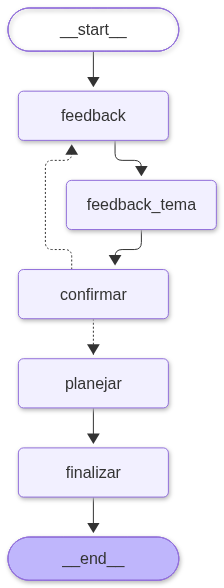

In [9]:
from typing import TypedDict, Literal

from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command


class FeedbackState(TypedDict, total=False):
    tema: str
    nivel: str
    roteiro: str
    versao_final: str

def node_pedir_feedback(state: FeedbackState) -> FeedbackState:
    resposta = interrupt({
        "pergunta": (
            "Qual nível deseja? iniciante/intermediário/avançado. "
            "Deixe em branco para manter."
        ),
        "nivel_atual": state.get("nivel", "iniciante"),
    })

    if isinstance(resposta, str) and resposta.strip():
        return {"nivel": resposta.strip()}

    return {}


def node_feedback_tema(state: FeedbackState) -> FeedbackState:
    resposta = interrupt({
        "pergunta": "Qual tema deseja? Deixe em branco para manter.",
        "tema_atual": state.get("tema", ""),
    })

    if isinstance(resposta, str) and resposta.strip():
        return {"tema": resposta.strip()}

    return {}
    
def node_planejar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, bem didático."),
        HumanMessage(content=(
            f"Crie um roteiro em 5 tópicos sobre {state.get('tema', 'LangGraph')}. "
            f"Nível: {state.get('nivel', 'iniciante')}. "
            "Inclua 1 exemplo prático."
        )),
    ])
    return {"roteiro": resp.content}

def node_confirmar(
    state: FeedbackState,
) -> Command[Literal["planejar", "feedback"]]:
    pergunta = {
        "pergunta": (
            "Confirma o tema e o nível? "
            "Responda yes para gerar o material ou no para editar novamente."
        ),
        "tema": state.get("tema", ""),
        "nivel": state.get("nivel", "iniciante"),
    }

    resposta = interrupt(pergunta)

    while str(resposta).strip().casefold() not in {"yes", "no"}:
        resposta = interrupt({
            **pergunta,
            "erro": "Resposta inválida. Digite yes ou no.",
        })

    if str(resposta).strip().casefold() == "yes":
        return Command(goto="planejar")

    return Command(goto="feedback")

def node_finalizar(state: FeedbackState) -> FeedbackState:
    resp = llm.invoke([
        SystemMessage(content="Escreva em PT-BR, com estrutura para apostila."),
        HumanMessage(content=(
            "Transforme o roteiro em uma versão final formatada.\n\n"
            f"TEMA: {state.get('tema', '')}\n"
            f"NÍVEL: {state.get('nivel', 'iniciante')}\n"
            f"ROTEIRO:\n{state.get('roteiro', '')}\n\n"
            "Inclua uma seção 'Erros comuns' com 3 itens."
        )),
    ])
    return {"versao_final": resp.content}


fb_builder = StateGraph(FeedbackState)

fb_builder.add_node("feedback", node_pedir_feedback)
fb_builder.add_node("feedback_tema", node_feedback_tema)
fb_builder.add_node("confirmar", node_confirmar)
fb_builder.add_node("planejar", node_planejar)
fb_builder.add_node("finalizar", node_finalizar)

fb_builder.add_edge(START, "feedback")
fb_builder.add_edge("feedback", "feedback_tema")
fb_builder.add_edge("feedback_tema", "confirmar")
fb_builder.add_edge("planejar", "finalizar")
fb_builder.add_edge("finalizar", END)

fb_checkpointer = MemorySaver()
fb_graph = fb_builder.compile(checkpointer=fb_checkpointer)
fb_graph

In [10]:
fb_config = {"configurable": {"thread_id": "fb-celulas-01"}}

resultado = fb_graph.invoke(
    {"tema": "LangGraph", "nivel": "iniciante"},
    config=fb_config,
)

print(resultado["__interrupt__"][0].value)
#{'pergunta': 'Qual nível deseja? iniciante/intermediário/avançado. Deixe em branco para manter.', 'nivel_atual': 'iniciante'

{'pergunta': 'Qual nível deseja? iniciante/intermediário/avançado. Deixe em branco para manter.', 'nivel_atual': 'iniciante'}


In [11]:
nivel = input("Nível desejado (Enter para manter): ")

resultado = fb_graph.invoke(
    Command(resume=nivel),
    config=fb_config,
)

print(resultado["__interrupt__"][0].value)
#{'pergunta': 'Deseja mudar de tema? Deixe em branco para manter.', 'tema_atual': 'LangGraph'}n

{'pergunta': 'Qual tema deseja? Deixe em branco para manter.', 'tema_atual': 'LangGraph'}


In [12]:
tema = input("Tema desejado (Enter para manter): ")

resultado = fb_graph.invoke(
    Command(resume=tema),
    config=fb_config,
)

print(resultado["__interrupt__"][0].value)

{'pergunta': 'Confirma o tema e o nível? Responda yes para gerar o material ou no para editar novamente.', 'tema': 'Computação Quântica Aplicada a IA', 'nivel': 'avançado'}


In [13]:
confirmacao = input("Confirma o tema e o nível? (yes/no): ").strip().casefold()

while confirmacao not in {"yes", "no"}:
    confirmacao = input("Digite yes ou no: ").strip().casefold()

resultado = fb_graph.invoke(
    Command(resume=confirmacao),
    config=fb_config,
)

if resultado.get("__interrupt__"):
    print(resultado["__interrupt__"][0].value)
    print("\nExecute novamente as células 2, 3 e 4.")
else:
    print("Nível:", resultado["nivel"])
    print("Tema:", resultado["tema"])
    print(resultado["versao_final"])

Nível: avançado
Tema: Computação Quântica Aplicada a IA
# Apostila – Computação Quântica Aplicada à Inteligência Artificial  
**Nível:** avançado | **Linguagem:** PT‑BR  

---  

## Sumário  

1. [Fundamentos da Computação Quântica para IA](#1-fundamentos-da-computação-quântica-para-ia)  
2. [Algoritmos Quânticos que Potencializam IA](#2-algoritmos-quânticos-que-potencializam-ia)  
3. [Arquiteturas Híbridas: Classical‑Quantum Loop](#3-arquiteturas-híbridas-classical‑quantum-loop)  
4. [Desafios Práticos e Estratégias de Mitigação](#4-desafios-práticos-e-estratégias-de-mitigação)  
5. [Futuro da Computação Quântica em IA](#5-futuro-da-computação-quântica-em-ia)  
6. [Exemplo Prático – Classificador Quântico Variacional (Iris)](#6-exemplo‑prático---classificador-quântico-variacional-para-o‑dataset‑iris)  
7. [Erros Comuns](#7-erros‑comuns)  
8. [Referências e Bibliografia](#8-referências-e-bibliografia)  

---  

## 1. Fundamentos da Computação Quântica para IA  

| Subtópico | Conteúdo 